# Preferred Attack Direction — MLB & Frontier League

Marshall-style EV-envelope methodology, applied to the **horizontal** plane:

1. Mirror spray direction so **pull = positive for both hands**
2. Bin BBE by spray direction (3° bins over −45° to +45°)
3. Within each bin, keep the **top 20% of BBE by exit velocity**
4. Fit a parabola to the envelope; **Method 1** = spray direction at the peak
5. **Method 2** = mean spray direction of the **top 15 BBE by EV**
6. **PAD = average of Method 1 and Method 2**  (positive = pull-oriented power)

Conventions:
- **MLB**: Statcast parquet caches, spray from `hc_x`/`hc_y`. Ground-truth validation vs measured bat-tracking `attack_direction` (per-handedness sign check included — conventions verified empirically, not assumed).
- **FL**: Supabase, `pitch_call='in_play'`, `direction` (±45 filter), `batter_side` assert-mapped, `'undefined'` rows dropped.
- Pull = mirrored spray > 15°, Air = LA ≥ 10 — same validated conventions as the PAA notebook.

Outputs: batter-level correlations of PAD vs **Pull%, Air%, PullAir%** in both leagues.

## 1. Imports & Config

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
from scipy.stats import spearmanr
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.3f}".format)

# ── PAD methodology parameters ────────────────────────────────────────────────
SPRAY_MIN, SPRAY_MAX = -45, 45     # physical spray window (pull-positive after mirror)
BIN_WIDTH        = 3               # 3° spray bins (parallel to PAA's LA bins)
TOP_FRAC_PER_BIN = 0.20            # top 20% of BBE by EV within each bin
TOP_N_METHOD2    = 15              # method 2: mean spray of top-15 BBE by EV

# ── Qualification thresholds ──────────────────────────────────────────────────
MIN_BBE_MLB = 100
MIN_BBE_FL  = 50

# ── Spray / air conventions (validated previously) ────────────────────────────
PULL_CUTOFF_DEG = 15
AIR_LA_MIN      = 10

print("Config OK")

Config OK


## 2. Preferred Attack Direction — Methodology

Identical envelope machinery to PAA, but x = mirrored spray direction. Works on a
`spray_pull` column (pull-positive for both hands) that each league section constructs.

In [2]:
def preferred_attack_direction(df, spray_col, ev_col):
    """
    EV-envelope Preferred Attack Direction for a single batter's BBE.
    spray_col must already be mirrored pull-positive.

    Method 1: 3° spray bins → top 20% by EV per bin → parabola fit → peak.
    Method 2: mean spray of the top-15 BBE by EV.
    PAD      = mean(Method 1, Method 2).

    Returns (pad, method1, method2, n_envelope).
    """
    g = df.dropna(subset=[spray_col, ev_col])
    g = g[(g[spray_col] >= SPRAY_MIN) & (g[spray_col] <= SPRAY_MAX)]
    if len(g) < 10:
        return np.nan, np.nan, np.nan, 0

    k2 = min(TOP_N_METHOD2, max(3, int(np.ceil(0.2 * len(g)))))
    method2 = g.nlargest(k2, ev_col)[spray_col].mean()

    bins = np.arange(SPRAY_MIN, SPRAY_MAX + BIN_WIDTH, BIN_WIDTH)
    g = g.copy()
    g["_bin"] = pd.cut(g[spray_col], bins=bins, include_lowest=True)

    env_idx = []
    for _, grp in g.groupby("_bin", observed=True):
        if len(grp) == 0:
            continue
        k = max(1, int(np.ceil(TOP_FRAC_PER_BIN * len(grp))))
        env_idx.extend(grp.nlargest(k, ev_col).index)

    env = g.loc[env_idx]
    if len(env) < 5:
        return method2, np.nan, method2, len(env)

    a, b, c = np.polyfit(env[spray_col], env[ev_col], deg=2)

    if a < 0:
        vertex = -b / (2 * a)
        if SPRAY_MIN <= vertex <= SPRAY_MAX:
            method1 = vertex
        else:
            xs = np.linspace(SPRAY_MIN, SPRAY_MAX, 361)
            method1 = xs[np.argmax(np.polyval([a, b, c], xs))]
    else:
        method1 = env.loc[env[ev_col].idxmax(), spray_col]

    pad = np.nanmean([method1, method2])
    return pad, method1, method2, len(env)


def batter_pad_table(df, batter_col, spray_col, ev_col):
    rows = []
    for batter, g in df.groupby(batter_col):
        pad, m1, m2, n_env = preferred_attack_direction(g, spray_col, ev_col)
        rows.append({
            batter_col: batter,
            "PAD": pad, "PAD_parabola": m1, "PAD_top15": m2,
            "BBE": len(g.dropna(subset=[spray_col, ev_col])),
            "n_envelope": n_env,
        })
    return pd.DataFrame(rows)

print("PAD functions defined")

PAD functions defined


## 3. MLB — Load Statcast & Build Mirrored Spray

In [3]:
def load_statcast(cache_path):
    p = Path(cache_path)
    if p.exists():
        print(f"Loading {p} …")
        return pd.read_parquet(p)
    raise FileNotFoundError(f"{p} not found — build the cache first.")

raw = pd.concat([
    load_statcast("statcast_2024.parquet"),
    load_statcast("statcast_2025.parquet"),
], ignore_index=True)

mlb = raw[
    (raw["type"] == "X") &
    raw["launch_speed"].notna() &
    raw["launch_angle"].notna() &
    raw["hc_x"].notna() & raw["hc_y"].notna() &
    raw["stand"].notna() &
    raw["batter"].notna()
].copy()

# Spray angle (deg): negative = LF side, positive = RF side
mlb["spray_deg"] = np.degrees(
    np.arctan((mlb["hc_x"] - 125.42) / (198.27 - mlb["hc_y"]))
) * 0.75

# Mirror → pull-positive for both hands (RHB pull = LF = negative spray)
mlb["spray_pull"] = np.where(mlb["stand"] == "R",
                             -mlb["spray_deg"], mlb["spray_deg"])

mlb["is_pull"] = mlb["spray_pull"] > PULL_CUTOFF_DEG
mlb["is_air"]  = mlb["launch_angle"] >= AIR_LA_MIN

print(f"MLB BBE rows: {len(mlb):,}   batters: {mlb['batter'].nunique():,}")
print(f"MLB league Pull%    : {mlb['is_pull'].mean():.3f}   (expect ≈ .36)")
print(f"MLB league PullAir% : {(mlb['is_pull'] & mlb['is_air']).mean():.3f}")

Loading statcast_2024.parquet …
Loading statcast_2025.parquet …
MLB BBE rows: 252,710   batters: 1,241
MLB league Pull%    : 0.380   (expect ≈ .36)
MLB league PullAir% : 0.152


## 4. MLB — PAD per Batter

In [4]:
mlb_pad = batter_pad_table(mlb, "batter", "spray_pull", "launch_speed")

mlb_spray = mlb.groupby("batter").agg(
    pull_pct = ("is_pull", "mean"),
    air_pct  = ("is_air",  "mean"),
).reset_index()
mlb_pullair = mlb.groupby("batter").apply(
    lambda g: (g["is_pull"] & g["is_air"]).mean()
).rename("pull_air_pct").reset_index()

mlb_batters = (mlb_pad
    .merge(mlb_spray, on="batter")
    .merge(mlb_pullair, on="batter"))
mlb_q = mlb_batters[(mlb_batters["BBE"] >= MIN_BBE_MLB) &
                    mlb_batters["PAD"].notna()].copy()
print(f"Qualified MLB batters (≥{MIN_BBE_MLB} BBE): {len(mlb_q)}")
print(mlb_q["PAD"].describe().round(2))

Qualified MLB batters (≥100 BBE): 522
count   522.000
mean     11.560
std       5.540
min      -8.570
25%       8.040
50%      11.790
75%      15.250
max      32.550
Name: PAD, dtype: float64


### 4b. Ground-truth validation — PAD vs measured `attack_direction`

Statcast's bat-tracking `attack_direction` sign convention is **verified empirically
per handedness**, not assumed: we mirror it both ways and keep whichever direction
correlates positively with observed spray for each side. If the two hands disagree
after mirroring, that's a red flag printed loudly.

── attack_direction vs spray_deg, by handedness (raw signs) ──
  RHB (n=132,809): r = +0.396
  LHB (n=99,759): r = -0.360
Positive r for both → attack_direction shares spray_deg's sign (neg = LF side); mirror with the same rule as spray.

PAD vs measured attack direction (n=522):
  Pearson r  = 0.5038
  Spearman ρ = 0.4927   (p = 2.82e-33)


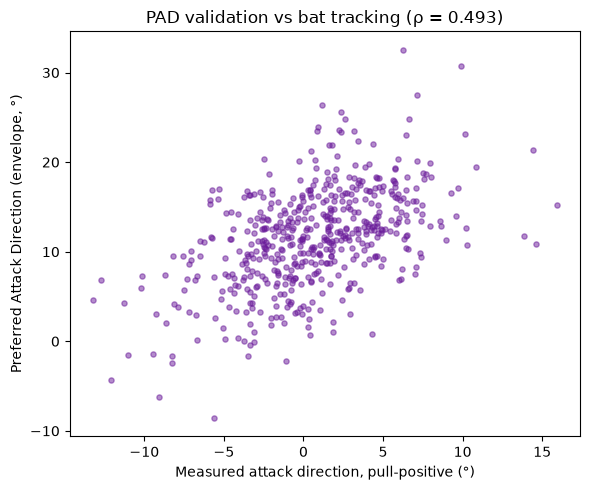

In [5]:
if "attack_direction" in raw.columns and raw["attack_direction"].notna().any():
    ad = raw[raw["attack_direction"].notna() &
             raw["batter"].notna() &
             raw["stand"].notna()].copy()

    # Empirical sign check: correlate raw attack_direction with raw spray_deg
    # (contact events only) per handedness.
    ad_bbe = ad[(ad["type"] == "X") & ad["hc_x"].notna() & ad["hc_y"].notna()].copy()
    ad_bbe["spray_deg"] = np.degrees(
        np.arctan((ad_bbe["hc_x"] - 125.42) / (198.27 - ad_bbe["hc_y"]))) * 0.75

    print("── attack_direction vs spray_deg, by handedness (raw signs) ──")
    signs = {}
    for side in ["R", "L"]:
        sub = ad_bbe[ad_bbe["stand"] == side]
        r = sub[["attack_direction", "spray_deg"]].corr().iloc[0, 1]
        signs[side] = np.sign(r)
        print(f"  {side}HB (n={len(sub):,}): r = {r:+.3f}")
    print("Positive r for both → attack_direction shares spray_deg's sign "
          "(neg = LF side); mirror with the same rule as spray.")

    # Mirror measured attack_direction to pull-positive using the verified sign
    ad["ad_pull"] = np.where(
        ad["stand"] == "R",
        -ad["attack_direction"] * signs["R"],
         ad["attack_direction"] * signs["L"],
    )

    ad_batter = (ad.groupby("batter")["ad_pull"]
                 .agg(["mean", "count"])
                 .rename(columns={"mean": "ad_measured", "count": "n_swings"})
                 .reset_index())

    chk = mlb_q.merge(ad_batter[ad_batter["n_swings"] >= 100], on="batter")
    r_p, _   = stats.pearsonr(chk["PAD"], chk["ad_measured"])
    r_s, p_s = spearmanr(chk["PAD"], chk["ad_measured"])
    print(f"\nPAD vs measured attack direction (n={len(chk)}):")
    print(f"  Pearson r  = {r_p:.4f}")
    print(f"  Spearman ρ = {r_s:.4f}   (p = {p_s:.2e})")

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.scatter(chk["ad_measured"], chk["PAD"], s=14, alpha=0.5, color="#6A1B9A")
    ax.set_xlabel("Measured attack direction, pull-positive (°)")
    ax.set_ylabel("Preferred Attack Direction (envelope, °)")
    ax.set_title(f"PAD validation vs bat tracking (ρ = {r_s:.3f})")
    plt.tight_layout(); plt.show()
else:
    print("attack_direction not in cache — skipping ground-truth validation")

## 5. MLB — Correlations: PAD vs Pull%, Air%, PullAir%

In [6]:
def corr_table(df, x_col, targets, label):
    print(f"{label}  (n={len(df)})")
    print(f"{'Metric':<12}  {'Pearson r':>10}  {'Spearman ρ':>10}  {'p-value':>10}")
    print("-" * 50)
    out = {}
    for name, col in targets.items():
        paired = df[[x_col, col]].dropna()
        r_p, _   = stats.pearsonr(paired[x_col], paired[col])
        r_s, p_s = spearmanr(paired[x_col], paired[col])
        print(f"{name:<12}  {r_p:>10.4f}  {r_s:>10.4f}  {p_s:>10.2e}")
        out[name] = (r_p, r_s, p_s)
    return out

TARGETS = {"Pull%": "pull_pct", "Air%": "air_pct", "PullAir%": "pull_air_pct"}

mlb_corrs = corr_table(mlb_q, "PAD", TARGETS,
                       f"MLB — PAD correlations (≥{MIN_BBE_MLB} BBE, 2024-25 pooled)")

MLB — PAD correlations (≥100 BBE, 2024-25 pooled)  (n=522)
Metric         Pearson r  Spearman ρ     p-value
--------------------------------------------------
Pull%             0.5451      0.5131    2.18e-36
Air%              0.4954      0.4702    4.56e-30
PullAir%          0.5732      0.5596    2.41e-44


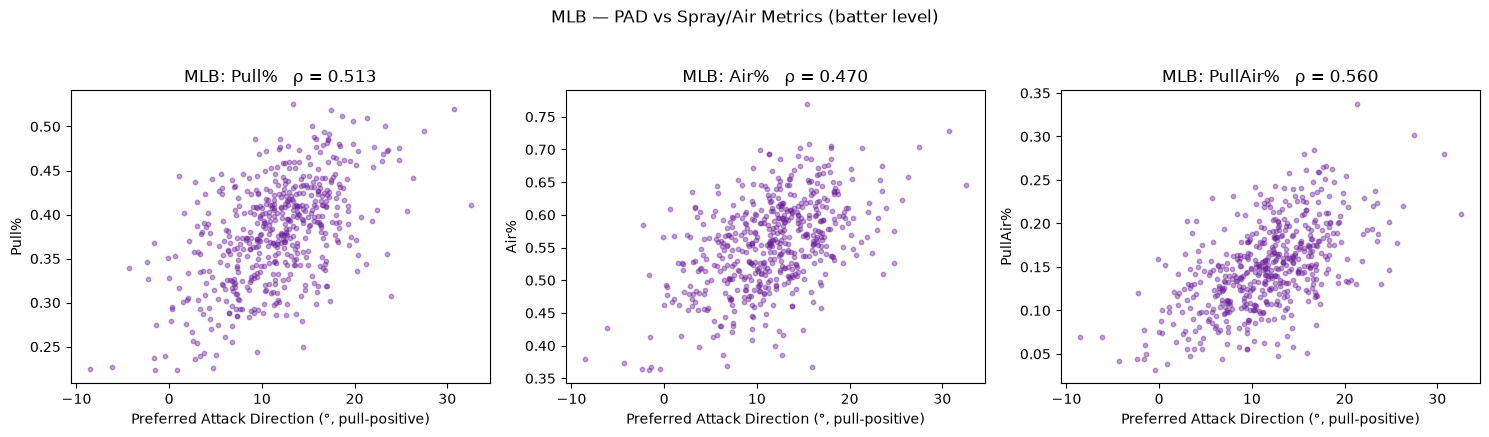

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (name, col) in zip(axes, TARGETS.items()):
    ax.scatter(mlb_q["PAD"], mlb_q[col], s=10, alpha=0.4, color="#6A1B9A")
    r_s, _ = spearmanr(mlb_q["PAD"], mlb_q[col])
    ax.set_xlabel("Preferred Attack Direction (°, pull-positive)")
    ax.set_ylabel(name)
    ax.set_title(f"MLB: {name}   ρ = {r_s:.3f}")
plt.suptitle("MLB — PAD vs Spray/Air Metrics (batter level)", y=1.03)
plt.tight_layout(); plt.show()

## 6. Frontier League — Pull from Supabase

In [8]:
ENV_PATH = r"C:/Users/215nt/PycharmProjects/FLStuff/FLPitching/FLCommand/.env"

def get_engine():
    load_dotenv(ENV_PATH)
    host     = os.getenv("SUPABASE_HOST", "aws-1-us-east-1.pooler.supabase.com")
    port     = os.getenv("SUPABASE_PORT", "6543")
    dbname   = os.getenv("SUPABASE_DB",   "postgres")
    user     = os.getenv("SUPABASE_USER")
    password = os.getenv("SUPABASE_PASSWORD")
    return create_engine(
        f"postgresql+psycopg2://{user}:{password}@{host}:{port}/{dbname}?sslmode=require"
    )

SQL = """
SELECT
    batter,
    batter_team,
    batter_side,
    year,
    exit_speed,
    angle,
    direction
FROM pitches
WHERE pitch_call = 'in_play'
  AND exit_speed IS NOT NULL
  AND angle      IS NOT NULL
  AND direction  IS NOT NULL
  AND batter     IS NOT NULL
"""

engine = get_engine()
with engine.connect() as conn:
    fl_raw = pd.read_sql(text(SQL), conn)

print(f"FL BBE rows: {len(fl_raw):,}   batters: {fl_raw['batter'].nunique()}")
print(f"Years: {sorted(fl_raw['year'].unique())}")

FL BBE rows: 65,420   batters: 584
Years: [np.float64(2025.0), np.float64(2026.0), np.float64(nan)]


## 7. FL — Conventions & Mirrored Spray

In [9]:
FL_HAND_MAP = {"Left": "L", "Right": "R", "left": "L", "right": "R"}

n_before = len(fl_raw)
fl_raw = fl_raw[fl_raw["batter_side"] != "undefined"].copy()
print(f"Dropped {n_before - len(fl_raw):,} rows with undefined batter_side")

unmapped = fl_raw.loc[~fl_raw["batter_side"].isin(FL_HAND_MAP), "batter_side"].unique()
assert len(unmapped) == 0, f"Unmapped batter_side values: {list(unmapped)} — add to FL_HAND_MAP"

fl = fl_raw.copy()
fl["stand"] = fl["batter_side"].map(FL_HAND_MAP)

n_before = len(fl)
fl = fl[fl["direction"].between(-45, 45)].copy()
print(f"Direction outlier filter: dropped {n_before - len(fl):,} rows")

# Mirror → pull-positive (validated: RHB pull = direction < −15)
fl["spray_pull"] = np.where(fl["stand"] == "R",
                            -fl["direction"], fl["direction"])

fl["is_pull"] = fl["spray_pull"] > PULL_CUTOFF_DEG
fl["is_air"]  = fl["angle"] >= AIR_LA_MIN

print(f"FL league Pull%    : {fl['is_pull'].mean():.3f}   (expect ≈ .36)")
print(f"FL league Air%     : {fl['is_air'].mean():.3f}")
print(f"FL league PullAir% : {(fl['is_pull'] & fl['is_air']).mean():.3f}")

Dropped 25 rows with undefined batter_side
Direction outlier filter: dropped 4,314 rows
FL league Pull%    : 0.360   (expect ≈ .36)
FL league Air%     : 0.565
FL league PullAir% : 0.157


## 8. FL — PAD per Batter & Correlations

In [10]:
fl_pad = batter_pad_table(fl, "batter", "spray_pull", "exit_speed")

fl_spray = fl.groupby("batter").agg(
    pull_pct = ("is_pull", "mean"),
    air_pct  = ("is_air",  "mean"),
).reset_index()
fl_pullair = fl.groupby("batter").apply(
    lambda g: (g["is_pull"] & g["is_air"]).mean()
).rename("pull_air_pct").reset_index()

fl_batters = (fl_pad
    .merge(fl_spray, on="batter")
    .merge(fl_pullair, on="batter"))
fl_q = fl_batters[(fl_batters["BBE"] >= MIN_BBE_FL) &
                  fl_batters["PAD"].notna()].copy()
print(f"Qualified FL batters (≥{MIN_BBE_FL} BBE): {len(fl_q)}")
print(fl_q["PAD"].describe().round(2))

Qualified FL batters (≥50 BBE): 317
count   317.000
mean     11.460
std       6.870
min     -11.190
25%       7.700
50%      11.500
75%      14.970
max      35.150
Name: PAD, dtype: float64


Frontier League — PAD correlations (≥50 BBE)  (n=317)
Metric         Pearson r  Spearman ρ     p-value
--------------------------------------------------
Pull%             0.6385      0.6411    4.29e-38
Air%              0.3296      0.3402    4.99e-10
PullAir%          0.5912      0.6124    5.17e-34


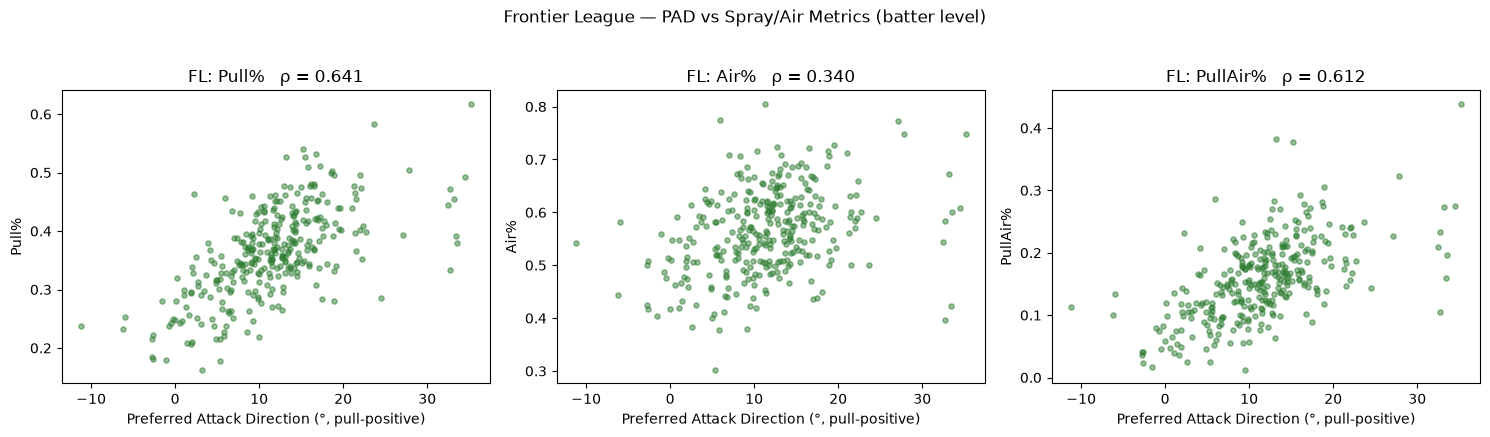

In [11]:
fl_corrs = corr_table(fl_q, "PAD", TARGETS,
                      f"Frontier League — PAD correlations (≥{MIN_BBE_FL} BBE)")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (name, col) in zip(axes, TARGETS.items()):
    ax.scatter(fl_q["PAD"], fl_q[col], s=14, alpha=0.5, color="#2E7D32")
    r_s, _ = spearmanr(fl_q["PAD"], fl_q[col])
    ax.set_xlabel("Preferred Attack Direction (°, pull-positive)")
    ax.set_ylabel(name)
    ax.set_title(f"FL: {name}   ρ = {r_s:.3f}")
plt.suptitle("Frontier League — PAD vs Spray/Air Metrics (batter level)", y=1.03)
plt.tight_layout(); plt.show()

## 9. Side-by-Side Summary & Save

League   Metric   n  Pearson r  Spearman ρ  p-value
   MLB    Pull% 522      0.545       0.513 2.18e-36
   MLB     Air% 522      0.495       0.470 4.56e-30
   MLB PullAir% 522      0.573       0.560 2.41e-44
    FL    Pull% 317      0.638       0.641 4.29e-38
    FL     Air% 317      0.330       0.340 4.99e-10
    FL PullAir% 317      0.591       0.612 5.17e-34


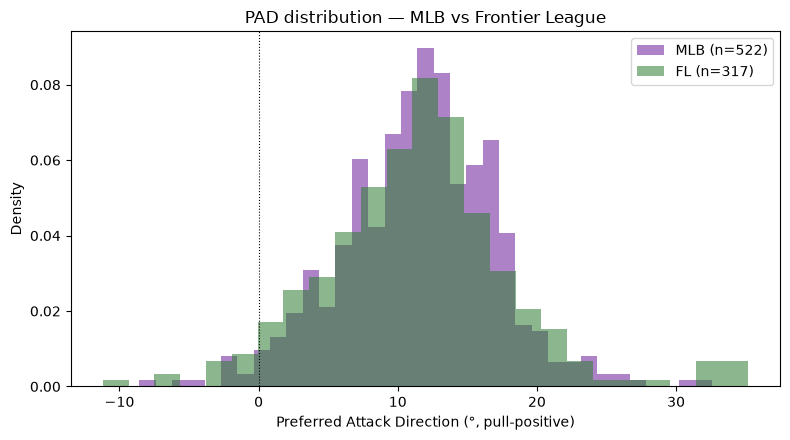


Saved → output/pad_mlb.csv, output/pad_fl.csv


In [12]:
summary_rows = []
for league, corrs, n in [("MLB", mlb_corrs, len(mlb_q)), ("FL", fl_corrs, len(fl_q))]:
    for metric, (r_p, r_s, p) in corrs.items():
        summary_rows.append({"League": league, "Metric": metric, "n": n,
                             "Pearson r": round(r_p, 4),
                             "Spearman ρ": round(r_s, 4),
                             "p-value": f"{p:.2e}"})
summary = pd.DataFrame(summary_rows)
print(summary.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(mlb_q["PAD"], bins=35, alpha=0.55, density=True, color="#6A1B9A", label=f"MLB (n={len(mlb_q)})")
ax.hist(fl_q["PAD"],  bins=25, alpha=0.55, density=True, color="#2E7D32", label=f"FL (n={len(fl_q)})")
ax.axvline(0, color="black", lw=0.8, ls=":")
ax.set_xlabel("Preferred Attack Direction (°, pull-positive)")
ax.set_ylabel("Density")
ax.set_title("PAD distribution — MLB vs Frontier League")
ax.legend(); plt.tight_layout(); plt.show()

Path("output").mkdir(exist_ok=True)
mlb_q.sort_values("PAD", ascending=False).to_csv("output/pad_mlb.csv", index=False)
fl_q.sort_values("PAD", ascending=False).to_csv("output/pad_fl.csv", index=False)
print("\nSaved → output/pad_mlb.csv, output/pad_fl.csv")

## 10. Optional — Joint PAA × PAD view

If you've run the PAA notebook and have `output/paa_mlb.csv` / `output/paa_fl.csv`,
this merges the two axes: **PAD (horizontal power direction) × PAA (vertical power
plane)** — the two swing-derived components of PullAir%.


MLB — PullAir% explained (n=522):
  PAD alone : R² = 0.329
  PAA alone : R² = 0.239
  PAD + PAA : R² = 0.475


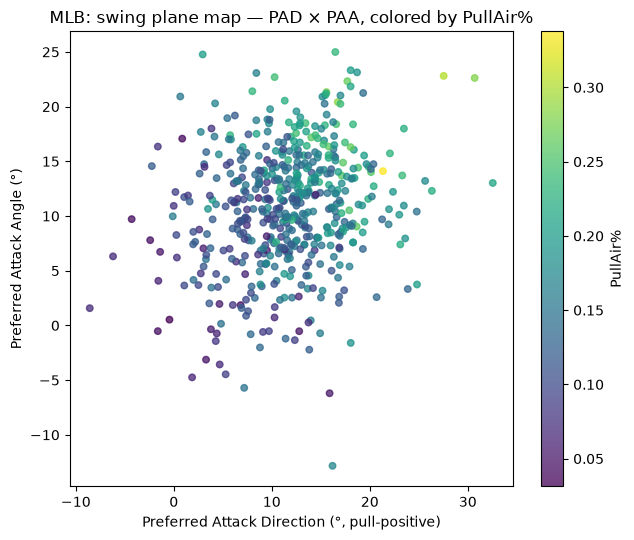


FL — PullAir% explained (n=317):
  PAD alone : R² = 0.350
  PAA alone : R² = 0.226
  PAD + PAA : R² = 0.528


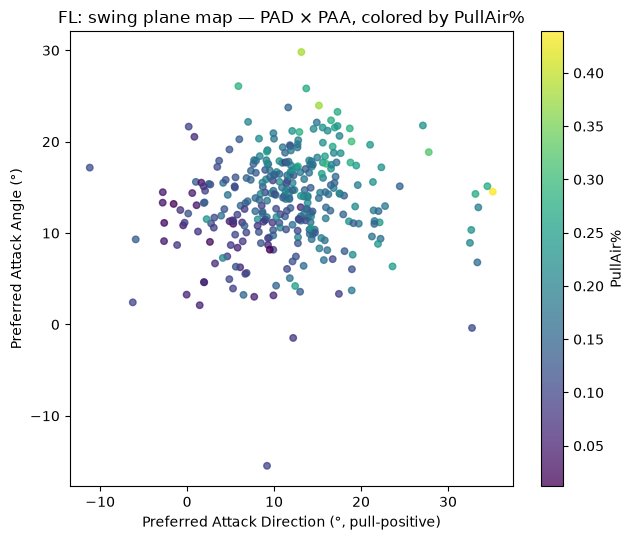

In [13]:
for league, pad_df, paa_path, color in [
    ("MLB", mlb_q, "output/paa_mlb.csv", "#6A1B9A"),
    ("FL",  fl_q,  "output/paa_fl.csv",  "#2E7D32"),
]:
    p = Path(paa_path)
    if not p.exists():
        print(f"{paa_path} not found — run the PAA notebook first. Skipping {league}.")
        continue
    paa_df = pd.read_csv(p)
    joint = pad_df.merge(paa_df[["batter", "PAA"]], on="batter").dropna(subset=["PAA", "PAD"])

    # Does PAD + PAA jointly explain PullAir% better than either alone?
    from sklearn.linear_model import LinearRegression
    X_pad  = joint[["PAD"]].values
    X_paa  = joint[["PAA"]].values
    X_both = joint[["PAD", "PAA"]].values
    y      = joint["pull_air_pct"].values

    r2_pad  = LinearRegression().fit(X_pad,  y).score(X_pad,  y)
    r2_paa  = LinearRegression().fit(X_paa,  y).score(X_paa,  y)
    r2_both = LinearRegression().fit(X_both, y).score(X_both, y)

    print(f"\n{league} — PullAir% explained (n={len(joint)}):")
    print(f"  PAD alone : R² = {r2_pad:.3f}")
    print(f"  PAA alone : R² = {r2_paa:.3f}")
    print(f"  PAD + PAA : R² = {r2_both:.3f}")

    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    sc = ax.scatter(joint["PAD"], joint["PAA"], c=joint["pull_air_pct"],
                    cmap="viridis", s=22, alpha=0.75)
    plt.colorbar(sc, ax=ax, label="PullAir%")
    ax.set_xlabel("Preferred Attack Direction (°, pull-positive)")
    ax.set_ylabel("Preferred Attack Angle (°)")
    ax.set_title(f"{league}: swing plane map — PAD × PAA, colored by PullAir%")
    plt.tight_layout(); plt.show()